[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/grabuffo/brain-modeling-course/blob/main/notebooks/D1_C1_NB01_hodgkin_huxley.ipynb)

# Day 1 · Chapter 1 · Notebook 01 — The Hodgkin–Huxley neuron

**Goal.** See what a single biophysical neuron does when we perturb it: subthreshold responses,
the all-or-none spike, refractoriness, repetitive firing and the f–I curve.

**Where we are on the ladder of models.**

| detailed morphology (Blue Brain) | **Hodgkin–Huxley** | 2D reductions | QIF / LIF | phase models |
|---|---|---|---|---|
| thousands of compartments | **1 compartment, 4 variables** | 2 variables | 1 variable | 1 angle |

Hodgkin and Huxley (1952) did not model molecules, dendrites or noise. They asked a question:
*can voltage-dependent Na⁺ and K⁺ conductances explain the action potential?*
Their model answered it, and predicted the spike shape and conduction speed from fitted
voltage-clamp data (Nobel Prize 1963). It is a good example of a model built for a purpose.

In [8]:
# --- Setup (run once) -------------------------------------------------------
# On Google Colab this downloads the course code; on your laptop it does nothing.
import sys, os
if "google.colab" in sys.modules and not os.path.exists("brain-modeling-course"):
    !git clone -q https://github.com/grabuffo/brain-modeling-course.git
    %cd brain-modeling-course/notebooks
    !pip -q install numba ipywidgets
sys.path.insert(0, os.path.abspath(".."))   # so that `import src` works

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact
from src import plotting
from src.plotting import slider
plotting.setup()
from src import neurons

## 1. The membrane as an electrical circuit

The membrane is a capacitor $C$ (the lipid bilayer) in parallel with three conductances
(sodium channels, potassium channels and a passive "leak"). Each conductance pushes the voltage
toward its own reversal potential $E_\text{Na}$, $E_\text{K}$, $E_L$:

$$
C\,\frac{dV}{dt} = I_\text{ext}
\;-\; \underbrace{g_\text{Na}\, m^3 h\,(V-E_\text{Na})}_{I_\text{Na}}
\;-\; \underbrace{g_\text{K}\, n^4\,(V-E_\text{K})}_{I_\text{K}}
\;-\; \underbrace{g_L\,(V-E_L)}_{I_L}
$$

The channels open and close. Hodgkin and Huxley described each channel with *gates*
$m, h, n \in [0, 1]$ (the fraction of gates that are open):

$$
\frac{dx}{dt} = \alpha_x(V)\,(1-x) - \beta_x(V)\,x
\quad\Longleftrightarrow\quad
\frac{dx}{dt} = \frac{x_\infty(V) - x}{\tau_x(V)},\qquad x \in \{m, h, n\}
$$

with $x_\infty = \alpha_x/(\alpha_x+\beta_x)$ (where the gate wants to go) and
$\tau_x = 1/(\alpha_x+\beta_x)$ (how fast it gets there).

* $m$: Na⁺ **activation**, fast. Opens when $V$ rises.
* $h$: Na⁺ **inactivation**, slow. Closes when $V$ rises.
* $n$: K⁺ **activation**, slow. Opens when $V$ rises.

Parameters (squid giant axon, rest shifted to −65 mV): $C = 1\,\mu$F/cm²,
$g_\text{Na}=120$, $g_\text{K}=36$, $g_L=0.3$ mS/cm², $E_\text{Na}=50$, $E_\text{K}=-77$, $E_L=-54.4$ mV.

{'C': 1.0, 'gNa': 120.0, 'gK': 36.0, 'gL': 0.3, 'ENa': 50.0, 'EK': -77.0, 'EL': -54.387}


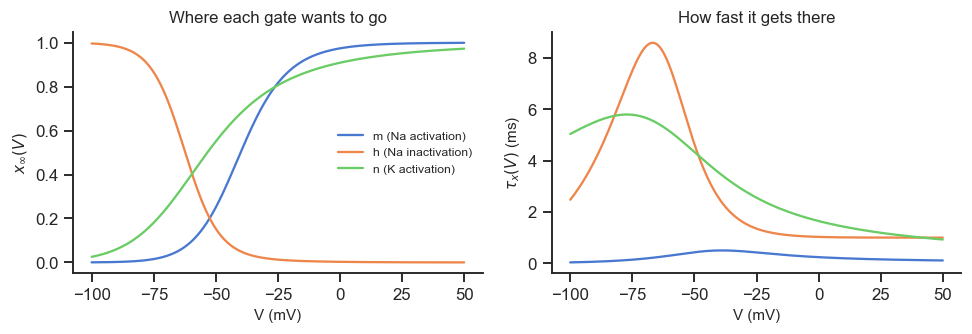

In [9]:
print(neurons.HH)
V = np.linspace(-100, 50, 400)
am, bm, ah, bh, an, bn = neurons.hh_rates(V)

fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
for (a, b, name) in [(am, bm, "m (Na activation)"), (ah, bh, "h (Na inactivation)"), (an, bn, "n (K activation)")]:
    ax[0].plot(V, a / (a + b), label=name)
    ax[1].plot(V, 1 / (a + b), label=name)
ax[0].set(xlabel="V (mV)", ylabel=r"$x_\infty(V)$", title="Where each gate wants to go")
ax[1].set(xlabel="V (mV)", ylabel=r"$\tau_x(V)$ (ms)", title="How fast it gets there")
ax[0].legend(fontsize=8)
plt.tight_layout()

**Read the plot.** $m$ is ~10 times faster than $h$ and $n$. When $V$ goes up, Na⁺ channels open
first (positive feedback: more Na⁺ in, higher $V$, more channels open), then $h$ closes them and $n$
opens K⁺ channels (negative feedback, the voltage comes back). **Fast positive feedback + slow
negative feedback** is the recipe for a spike, and we will meet it again in much simpler models.

### The equations in code

Here is the whole model in plain Python. Each line is one of the equations above; time advances with the
Euler step of NB00b, $x(t+\Delta t) = x(t) + \Delta t\,\frac{dx}{dt}$.

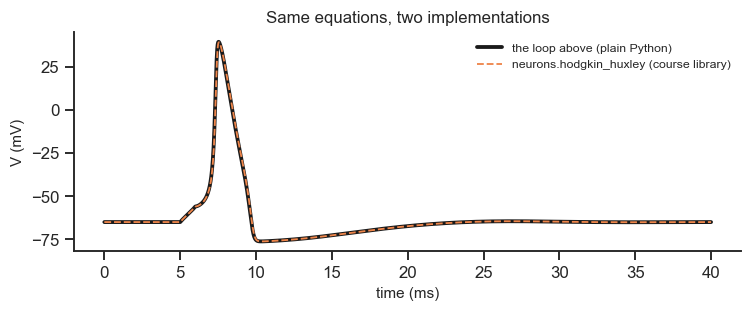

In [10]:
def hh_rates_py(V):
    # opening (alpha) and closing (beta) rates of the three gates, in 1/ms (Hodgkin & Huxley 1952)
    am = 0.1 * (V + 40) / (1 - np.exp(-(V + 40) / 10));   bm = 4 * np.exp(-(V + 65) / 18)
    ah = 0.07 * np.exp(-(V + 65) / 20);                   bh = 1 / (1 + np.exp(-(V + 35) / 10))
    an = 0.01 * (V + 55) / (1 - np.exp(-(V + 55) / 10));  bn = 0.125 * np.exp(-(V + 65) / 80)
    return am, bm, ah, bh, an, bn

def hh_step(V, m, h, n, I, dt, C=1.0, gNa=120.0, gK=36.0, gL=0.3, ENa=50.0, EK=-77.0, EL=-54.387):
    am, bm, ah, bh, an, bn = hh_rates_py(V)
    INa = gNa * m**3 * h * (V - ENa)        # sodium current
    IK = gK * n**4 * (V - EK)               # potassium current
    IL = gL * (V - EL)                      # leak current
    dV = (I - INa - IK - IL) / C            # C dV/dt = I - I_Na - I_K - I_L
    dm = am * (1 - m) - bm * m              # dx/dt = alpha_x (1 - x) - beta_x x
    dh = ah * (1 - h) - bh * h
    dn = an * (1 - n) - bn * n
    return V + dt * dV, m + dt * dm, h + dt * dh, n + dt * dn   # one Euler step

# simulate 40 ms with a 1 ms pulse at t = 5 ms
dt = 0.01                                  # ms
t = np.arange(0, 40, dt)
I = np.where((t >= 5) & (t < 6), 10.0, 0.0)
V = np.empty(len(t)); V[0] = -65.0
am, bm, ah, bh, an, bn = hh_rates_py(V[0])
m, h, n = am / (am + bm), ah / (ah + bh), an / (an + bn)   # gates start at rest (x = x_inf)
for k in range(len(t) - 1):
    V[k + 1], m, h, n = hh_step(V[k], m, h, n, I[k], dt)

V_lib, *_ = neurons.hodgkin_huxley(I, dt)  # the same model from the course library
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(t, V, "k", lw=2.5, label="the loop above (plain Python)")
ax.plot(t, V_lib, "C1--", lw=1.2, label="neurons.hodgkin_huxley (course library)")
ax.set(xlabel="time (ms)", ylabel="V (mV)", title="Same equations, two implementations")
ax.legend(fontsize=8)
plt.tight_layout()

The two curves overlap. The library function `neurons.hodgkin_huxley` (file `src/neurons.py`) contains the same loop,
compiled with `numba` so that it runs about 100 times faster; we use it from here on. Open the file whenever you want
to check how a model is coded.

## 2. Perturbation 1: short current pulses — the threshold

We inject a 1 ms pulse of increasing amplitude and watch the membrane potential.

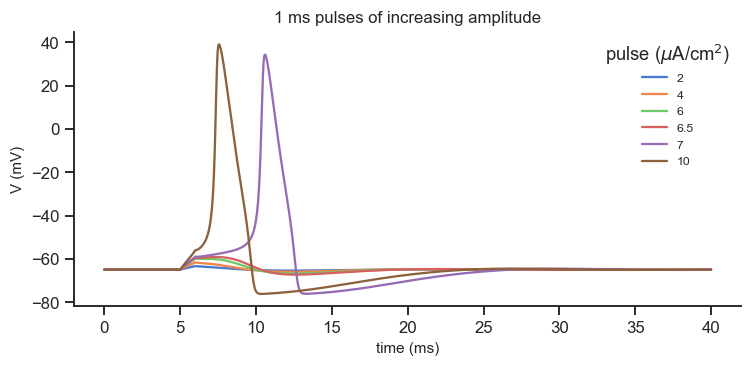

In [11]:
dt = 0.01                      # ms
t = np.arange(0, 40, dt)       # ms
amplitudes = [2, 4, 6, 6.5, 7, 10]   # uA/cm^2

fig, ax = plt.subplots(figsize=(7, 3.5))
for amp in amplitudes:
    I = np.where((t >= 5) & (t < 6), amp, 0.0)
    V, m, h, n = neurons.hodgkin_huxley(I, dt)
    ax.plot(t, V, label=f"{amp}")
ax.set(xlabel="time (ms)", ylabel="V (mV)", title="1 ms pulses of increasing amplitude")
ax.legend(title=r"pulse ($\mu$A/cm$^2$)", fontsize=8)
plt.tight_layout()

Small pulses give small, graded responses that decay back to rest. Above a threshold
(between 6.5 and 7 µA/cm² for a 1 ms pulse) the response jumps to a full spike of ~100 mV,
and making the pulse larger barely changes it. The spike is **all-or-none**.

### Explore: pulse amplitude and duration

Move the sliders (the figure updates when you release them).
* Find the threshold amplitude for a 1 ms pulse. Then make the pulse 0.2 ms and 3 ms long: does the threshold go up or down? Why?
* Watch the gates in the lower panel: which gate "decides" whether a spike happens?

In [12]:
@interact(amp=slider(5.0, 0.0, 30.0, 0.25, "pulse amplitude (uA/cm²)"),
          dur=slider(1.0, 0.1, 5.0, 0.1, "pulse duration (ms)"))
def explore_pulse(amp, dur):
    t = np.arange(0, 40, dt)
    I = np.where((t >= 5) & (t < 5 + dur), amp, 0.0)
    V, m, h, n = neurons.hodgkin_huxley(I, dt)
    fig, ax = plt.subplots(2, 1, figsize=(7, 4.5), sharex=True)
    ax[0].plot(t, V, "k"); ax[0].set(ylabel="V (mV)", ylim=(-85, 50),
        title="spike!" if V.max() > 0 else "no spike")
    ax[1].plot(t, m, label="m"); ax[1].plot(t, h, label="h"); ax[1].plot(t, n, label="n")
    ax[1].set(xlabel="time (ms)", ylabel="gate", ylim=(0, 1)); ax[1].legend(fontsize=8, ncol=3)
    plt.tight_layout(); plt.show()

interactive(children=(FloatSlider(value=5.0, continuous_update=False, description='pulse amplitude (uA/cm²)', …

## 3. Anatomy of a spike: gates and currents

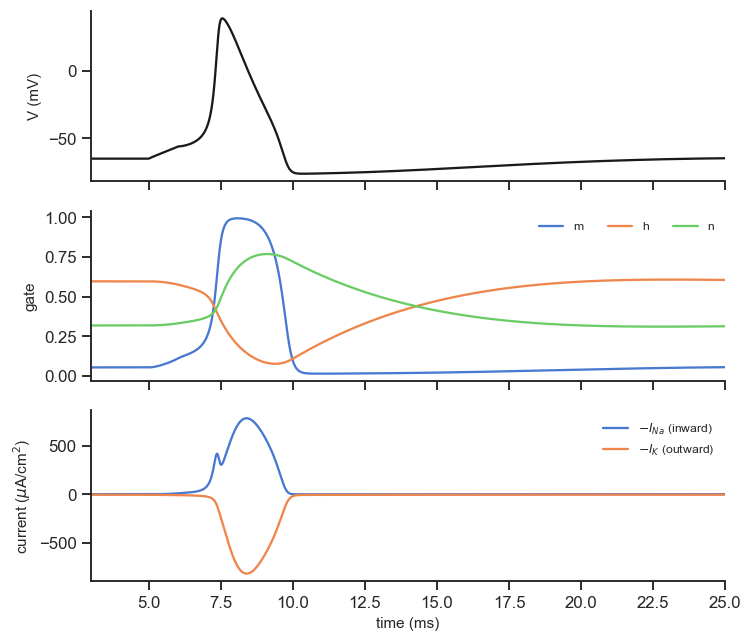

In [13]:
I = np.where((t >= 5) & (t < 6), 10.0, 0.0)
V, m, h, n = neurons.hodgkin_huxley(I, dt)
p = neurons.HH
INa = p["gNa"] * m**3 * h * (V - p["ENa"])
IK = p["gK"] * n**4 * (V - p["EK"])

fig, ax = plt.subplots(3, 1, figsize=(7, 6), sharex=True)
ax[0].plot(t, V, "k"); ax[0].set(ylabel="V (mV)")
ax[1].plot(t, m, label="m"); ax[1].plot(t, h, label="h"); ax[1].plot(t, n, label="n")
ax[1].set(ylabel="gate"); ax[1].legend(fontsize=8, ncol=3)
ax[2].plot(t, -INa, label=r"$-I_{Na}$ (inward)"); ax[2].plot(t, -IK, label=r"$-I_K$ (outward)")
ax[2].set(xlabel="time (ms)", ylabel=r"current ($\mu$A/cm$^2$)"); ax[2].legend(fontsize=8)
ax[0].set_xlim(3, 25)
plt.tight_layout()

1. $m$ shoots up: Na⁺ rushes in and depolarises the membrane (upstroke).
2. $h$ falls and $n$ rises: Na⁺ current switches off, K⁺ current flows out (downstroke).
3. $n$ stays high for a while: the voltage undershoots below rest (after-hyperpolarisation).
4. $h$ and $n$ recover slowly, which sets the **refractory period**.

## 4. Perturbation 2: two pulses — refractoriness

How strong must a second pulse be to trigger a second spike, as a function of the delay after
the first one? We find the threshold of the second pulse by bisection.

threshold of a single pulse: 6.95 uA/cm^2
no second spike possible (up to 200 uA/cm^2) for delays: [2 4 6] ms


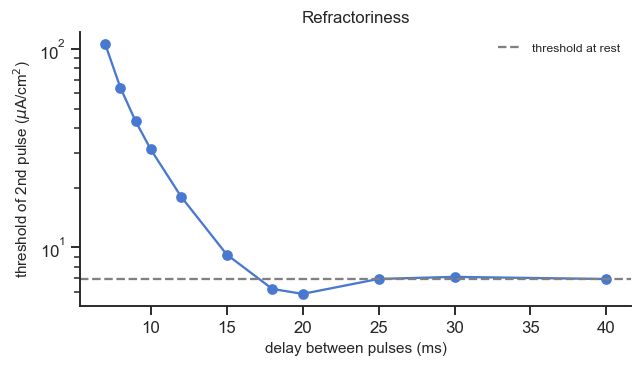

In [14]:
def fires_second_spike(amp2, isi, amp1=10.0, T=60.0):
    tt = np.arange(0, T, dt)
    I = np.where((tt >= 5) & (tt < 6), amp1, 0.0)
    I += np.where((tt >= 5 + isi) & (tt < 6 + isi), amp2, 0.0)
    V, *_ = neurons.hodgkin_huxley(I, dt)
    return len(neurons.spike_times(V, dt)) >= 2

def second_threshold(isi, lo=0.0, hi=200.0):
    if not fires_second_spike(hi, isi):
        return np.nan                      # absolutely refractory (within this range)
    for _ in range(20):
        mid = 0.5 * (lo + hi)
        lo, hi = (lo, mid) if fires_second_spike(mid, isi) else (mid, hi)
    return hi

def single_threshold(lo=0.0, hi=200.0):
    # threshold of one isolated 1 ms pulse, for reference
    for _ in range(20):
        mid = 0.5 * (lo + hi)
        I = np.where((t >= 5) & (t < 6), mid, 0.0)
        V, *_ = neurons.hodgkin_huxley(I, dt)
        lo, hi = (lo, mid) if len(neurons.spike_times(V, dt)) else (mid, hi)
    return hi

isis = np.array([2, 4, 6, 7, 8, 9, 10, 12, 15, 18, 20, 25, 30, 40])
thr = np.array([second_threshold(d) for d in isis])
thr_rest = single_threshold()
print(f"threshold of a single pulse: {thr_rest:.2f} uA/cm^2")
print("no second spike possible (up to 200 uA/cm^2) for delays:", isis[np.isnan(thr)], "ms")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(isis, thr, "o-")
ax.axhline(thr_rest, ls="--", c="gray", label="threshold at rest")
ax.set(xlabel="delay between pulses (ms)", ylabel=r"threshold of 2nd pulse ($\mu$A/cm$^2$)",
       yscale="log", title="Refractoriness")
ax.legend(fontsize=8)
plt.tight_layout()

Right after a spike no pulse in our range can produce another one (**absolute refractory period**,
the missing points). Later a second spike is possible but needs a stronger pulse (**relative
refractory period**). Around 20 ms the threshold even dips *below* its resting value
(a "supernormal" period, caused by the damped ringing of the membrane after the spike).
The neuron *remembers* its recent activity through the slow gates $h$ and $n$: the same
perturbation has a different effect depending on the state of the system. Keep this idea in mind
for Day 2, when we stimulate whole-brain models.

### Explore: two pulses

* Fix the delay at 10 ms and find the smallest second pulse that makes a spike. Is it on the curve above?
* Set the delay to 4 ms and push the second pulse to its maximum. Can you get a second spike?

In [15]:
@interact(delay=slider(10.0, 2.0, 40.0, 0.5, "delay (ms)"),
          amp2=slider(10.0, 0.0, 100.0, 0.5, "2nd pulse amplitude (uA/cm²)"))
def explore_two_pulses(delay, amp2):
    t = np.arange(0, 70, dt)
    I = np.where((t >= 5) & (t < 6), 10.0, 0.0) + np.where((t >= 5 + delay) & (t < 6 + delay), amp2, 0.0)
    V, m, h, n = neurons.hodgkin_huxley(I, dt)
    nsp = len(neurons.spike_times(V, dt))
    fig, ax = plt.subplots(2, 1, figsize=(7, 4), sharex=True, gridspec_kw=dict(height_ratios=[3, 1]))
    ax[0].plot(t, V, "k"); ax[0].set(ylabel="V (mV)", ylim=(-85, 50), title=f"{nsp} spike(s)")
    ax[1].plot(t, I, "C3"); ax[1].set(xlabel="time (ms)", ylabel="I")
    plt.tight_layout(); plt.show()

interactive(children=(FloatSlider(value=10.0, continuous_update=False, description='delay (ms)', layout=Layout…

## 5. Perturbation 3: constant current — repetitive firing

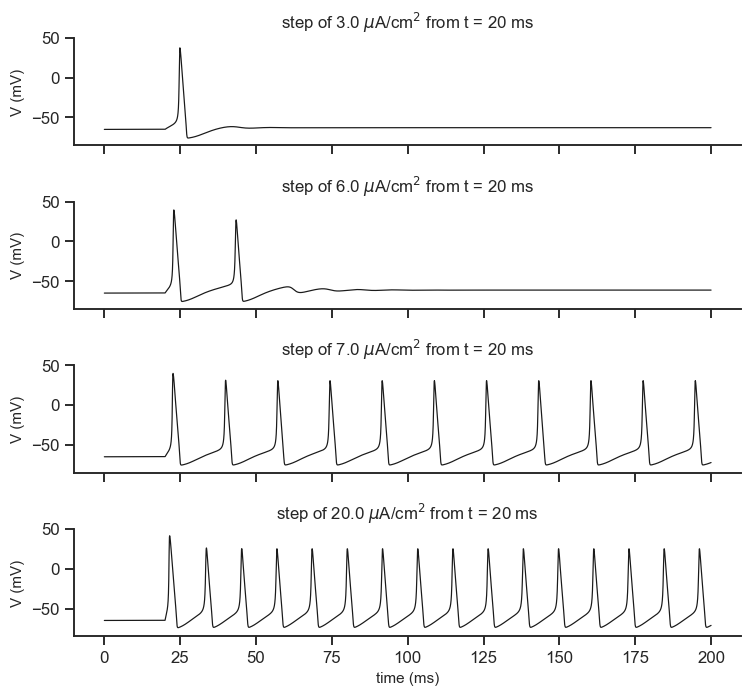

In [16]:
t_long = np.arange(0, 200, dt)
fig, ax = plt.subplots(4, 1, figsize=(7, 6.5), sharex=True)
for a_, I0 in zip(ax, [3.0, 6.0, 7.0, 20.0]):
    I = np.where(t_long >= 20, I0, 0.0)
    V, *_ = neurons.hodgkin_huxley(I, dt)
    a_.plot(t_long, V, "k", lw=0.8)
    a_.set(ylabel="V (mV)", title=fr"step of {I0} $\mu$A/cm$^2$ from t = 20 ms", ylim=(-85, 50))
ax[-1].set(xlabel="time (ms)")
plt.tight_layout()

* A sudden step can trigger one or two spikes even when it is too weak for sustained firing:
  HH reacts to *changes* of input, not only to its level. After that, the membrane settles to a new
  resting value through **damped oscillations** (it rings).
* Above a critical current the neuron fires **periodically**, forever.
* Stronger current gives faster firing.

## 6. The f–I curve: a qualitative change of behaviour

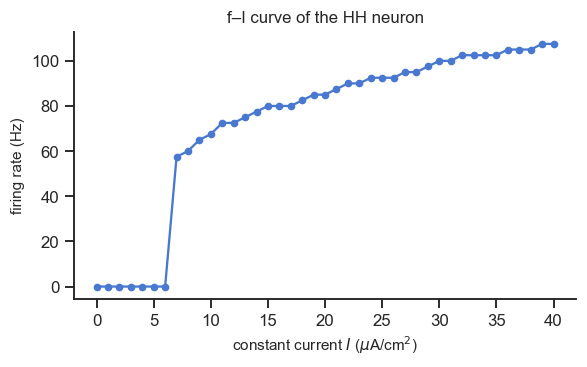

In [17]:
currents = np.linspace(0, 40, 41)
rates = neurons.hh_fi_curve(currents)      # firing rate after the initial transient

fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.plot(currents, rates, "o-", ms=4)
ax.set(xlabel=r"constant current $I$ ($\mu$A/cm$^2$)", ylabel="firing rate (Hz)", title="f–I curve of the HH neuron")
plt.tight_layout()

The HH neuron cannot fire slowly: at the critical current the rate **jumps** from 0 to ~50 Hz.
Below it the resting state is stable (with damped oscillations, section 5); above it a stable
oscillation (a *limit cycle*) appears with a finite frequency.

This is a **bifurcation**: a smooth change of a parameter ($I$) produces a qualitative change of
behaviour (rest → oscillation). For HH it is a **Hopf bifurcation** and the neuron is called
*type II* (Hodgkin 1948).

**An everyday picture: a swing.** A swing has its own rhythm, set by the length of its ropes. Push it too gently and it
wobbles back to rest (the damped ringing of section 5); push hard enough and it swings, but always at about the same
frequency: a swing cannot swing slowly. The HH neuron is the same: it has a preferred rhythm, it rings below threshold,
and it starts firing directly at ~50 Hz. In the next notebook we meet *type I* neurons, which can fire arbitrarily
slowly: they start oscillating through a different bifurcation (SNIC). We come back to
bifurcations in Chapter 4.

### Explore: the bifurcation in the phase plane

Here the current is raised **slowly** (a ramp over 300 ms, so the neuron is not startled by a sudden
step), then kept constant. At 350 ms you can give a short kick. Besides $V(t)$ we plot the trajectory in
the plane $(V, n)$ (voltage vs potassium gate) after 400 ms. A **fixed point** (rest) is a dot;
**repetitive firing** is a closed loop (a *limit cycle*).

* Without kick, increase $I$ step by step. At which value does the neuron start firing on its own?
* Does the loop appear small and grow, or directly with a large size? (Compare with the f–I curve: the rate also jumps.)
* Now set $I=8$ and give a kick. What happens? Is it the same neuron, with the same input, as without kick?

In [18]:
@interact(I0=slider(5.0, 0.0, 20.0, 0.1, "final current I (uA/cm²)"),
          kick=slider(0.0, 0.0, 30.0, 1.0, "kick at 350 ms (uA/cm², 1 ms)"))
def explore_bifurcation(I0, kick):
    t = np.arange(0, 700, dt)
    I = np.minimum(t / 300, 1) * I0 + np.where((t >= 350) & (t < 351), kick, 0.0)
    V, m, h, n = neurons.hodgkin_huxley(I, dt)
    keep = t > 400
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.5), gridspec_kw=dict(width_ratios=[2, 1]))
    ax[0].plot(t, V, "k", lw=0.8); ax[0].set(xlabel="time (ms)", ylabel="V (mV)", ylim=(-85, 50))
    ax[0].axvspan(0, 300, color="C0", alpha=0.08, label="ramp"); ax[0].axvline(350, c="C3", ls="--", lw=0.8, label="kick")
    ax[0].legend(fontsize=8, loc="upper left")
    ax[1].plot(V[keep], n[keep], "C0"); ax[1].plot(V[-1], n[-1], "o", c="C3")
    ax[1].set(xlabel="V (mV)", ylabel="n", xlim=(-85, 50), ylim=(0.2, 0.9), title="after 400 ms")
    nsp = np.sum(neurons.spike_times(V, dt) > 400)
    ax[0].set_title(f"firing at {nsp / 0.3:.0f} Hz" if nsp else "at rest")
    plt.tight_layout(); plt.show()

interactive(children=(FloatSlider(value=5.0, continuous_update=False, description='final current I (uA/cm²)', …

Between $I\approx 6.5$ and $I\approx 9.8$ µA/cm² the HH neuron is **bistable**: with the same input it
either rests or fires forever, depending on its history (the kick). The loop is born with a finite size
and a finite frequency, the hallmark of a *subcritical* Hopf bifurcation. This is also why a sudden
step of 7 µA/cm² in section 5 made the neuron fire: the step itself acted as a kick.
We return to bistability and hysteresis in Chapters 3 and 4.

## 7. Neurons talk through synapses: excitation and inhibition

So far we injected current with an electrode. In the brain, input arrives at **synapses**: a spike in the presynaptic neuron
releases a neurotransmitter, which opens ion channels in the membrane of the postsynaptic neuron. Like the Na and K
currents of section 1, a synaptic current pushes $V$ towards the **reversal potential** of its channels:

$$I_\text{syn}(t) = -\,g_\text{syn}(t)\,\big(V - E_\text{syn}\big)$$

* **Excitatory synapses.** The transmitter is **glutamate**; it opens AMPA (and NMDA) channels, permeable to Na⁺ and K⁺,
  with $E_\text{exc}\approx 0$ mV. They depolarise the cell: an excitatory postsynaptic potential (EPSP).
* **Inhibitory synapses.** The transmitter is **GABA**; it opens GABA$_A$ channels, permeable to Cl⁻, with
  $E_\text{inh}\approx -75$ mV, close to rest. They hyperpolarise the cell (IPSP), or simply hold it near rest.
* **Dale's principle.** A neuron releases the same transmitter at all its synapses, so each neuron is either excitatory or
  inhibitory. In the cortex about 80% of neurons are excitatory (pyramidal cells, whose axons also reach distant regions)
  and about 20% are inhibitory interneurons, mostly local, of several types (PV, SST, VIP...) that target different parts
  of other neurons (Markram et al. 2004).

Below, the HH neuron receives five presynaptic spikes 2 ms apart (each synapse: a conductance that jumps and decays with
3 ms for AMPA, 8 ms for GABA$_A$).

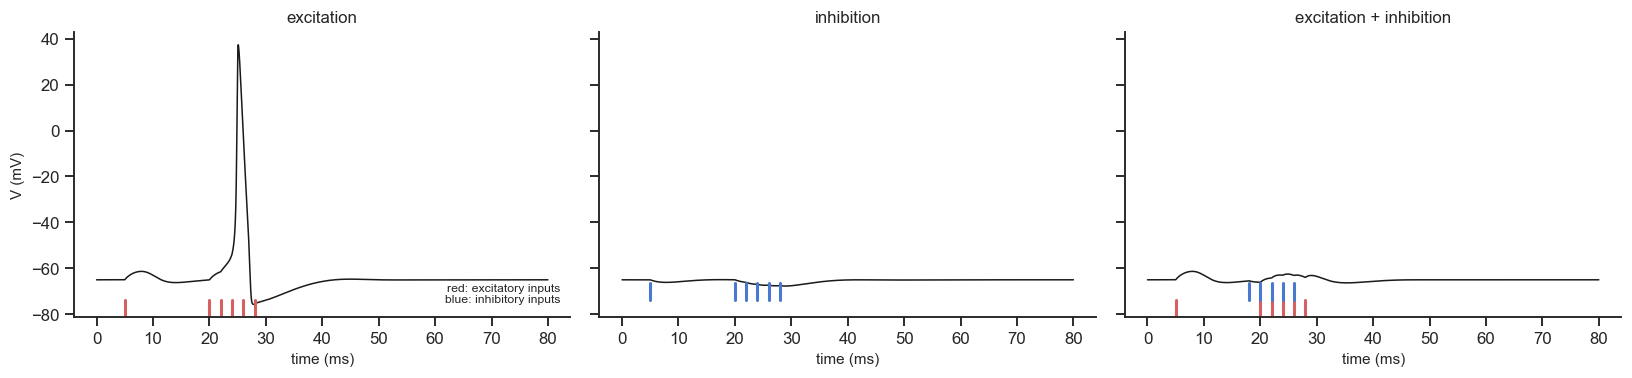

In [13]:
T = 80.0
t = np.arange(0, T, dt)
early = [5.0]                                        # one isolated input first
volley = [20.0, 22.0, 24.0, 26.0, 28.0]              # then five inputs 2 ms apart
cases = {"excitation": (early + volley, []), "inhibition": ([], early + volley), "excitation + inhibition": (early + volley, [18.0, 20.0, 22.0, 24.0, 26.0])}

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
for a_, (name, (spikes_e, spikes_i)) in zip(ax, cases.items()):
    gE = neurons.synaptic_conductance(spikes_e, T, dt, g_max=0.05, tau=3.0)
    gI = neurons.synaptic_conductance(spikes_i, T, dt, g_max=0.1, tau=8.0)
    V, *_ = neurons.hodgkin_huxley_syn(gE, gI, dt)
    a_.plot(t, V, "k", lw=1)
    for s_ in spikes_e: a_.axvline(s_, ymin=0, ymax=0.06, c="C3", lw=2)
    for s_ in spikes_i: a_.axvline(s_, ymin=0.06, ymax=0.12, c="C0", lw=2)
    a_.set(title=name, xlabel="time (ms)")
ax[0].set_ylabel("V (mV)")
ax[0].text(0.98, 0.05, "red: excitatory inputs\nblue: inhibitory inputs", transform=ax[0].transAxes, ha="right", fontsize=8)
plt.tight_layout()

* One excitatory input gives an EPSP of a few mV: far from threshold. Five arriving close together **add up** and the neuron
  fires (temporal summation).
* Inhibitory inputs pull $V$ down, towards $E_\text{inh}$.
* The same five excitatory inputs, with inhibition arriving at the same time, no longer make a spike: **inhibition vetoes
  excitation**. Its timing matters (try the slider below).

Every circuit of the brain mixes excitatory and inhibitory neurons, and the balance between the two sets how excitable a
circuit is. On Day 2 (NB07) we will see what a circuit of excitatory and inhibitory *populations* does: it oscillates.

### Explore: excitation, inhibition and timing
* How strong must excitation be to fire with no inhibition?
* With inhibition on, move it earlier and later than the excitation. When does it stop being able to veto the spike?

In [14]:
@interact(g_exc=slider(0.05, 0.0, 0.15, 0.005, "excitatory strength (mS/cm²)"),
          g_inh=slider(0.1, 0.0, 0.4, 0.01, "inhibitory strength (mS/cm²)"),
          shift=slider(-2.0, -20.0, 20.0, 1.0, "inhibition delay (ms)"))
def synapse_lab(g_exc, g_inh, shift):
    spikes_e = np.array(volley); spikes_i = spikes_e + shift
    gE = neurons.synaptic_conductance(spikes_e, T, dt, g_max=g_exc, tau=3.0)
    gI = neurons.synaptic_conductance(spikes_i, T, dt, g_max=g_inh, tau=8.0)
    V, *_ = neurons.hodgkin_huxley_syn(gE, gI, dt)
    fig, ax = plt.subplots(figsize=(8, 3))
    ax.plot(t, V, "k", lw=1)
    for s_ in spikes_e: ax.axvline(s_, ymin=0, ymax=0.06, c="C3", lw=2)
    for s_ in spikes_i: ax.axvline(s_, ymin=0.06, ymax=0.12, c="C0", lw=2)
    ax.set(xlabel="time (ms)", ylabel="V (mV)", ylim=(-85, 50), title="spike!" if V.max() > 0 else "no spike")
    plt.tight_layout(); plt.show()

interactive(children=(FloatSlider(value=0.05, continuous_update=False, description='excitatory strength (mS/cm…

## 8. Take-home

* HH explains the spike mechanistically: every variable and parameter has a biological meaning.
* The price: 4 coupled nonlinear equations and ~20 parameters. Simulating it is easy; *understanding*
  it (why threshold, why the jump in the f–I curve) needs the tools of dynamical systems.
* Networks of thousands of HH neurons are costly to simulate and impossible to analyse by hand.
* Neurons talk through synapses, and each neuron is either **excitatory** (glutamate) or **inhibitory** (GABA). Excitation
  adds up towards the threshold; inhibition, arriving at the right time, vetoes the spike.

**More detail gives more biological interpretability, but less mathematical interpretability and
less scalability.** Next notebook: what do we keep if we throw almost everything away?

### Homework
*To do at home, after the class. In class we use the **Explore** sliders; these exercises take the same
questions further and usually need a few lines of your own code.*
1. Inject a *negative* 5 ms pulse of −10 µA/cm² (write a few lines of code, starting from section 2). What happens when it ends? (anode-break excitation)
2. Find the smallest constant current that gives repetitive firing, to 0.1 µA/cm² precision.
3. Inject a slow ramp of current from 0 to 15 µA/cm² over 1 s and then back down to 0 over 1 s. At which current does the neuron start firing on the way up, and stop on the way down? Explain the difference with the bistability you found above (this is called *hysteresis*).
4. **How many inputs make a spike?** With the synapses of section 7, find the smallest number of simultaneous excitatory
   inputs that make the neuron fire. Then spread the same inputs over 10, 20 and 40 ms. What does this tell you about the
   importance of synchrony?

### References
* Markram H, Toledo-Rodriguez M, Wang Y, Gupta A, Silberberg G, Wu C (2004). Interneurons of the neocortical inhibitory system. *Nat Rev Neurosci* 5:793–807.
* Hodgkin AL, Huxley AF (1952). A quantitative description of membrane current and its application to conduction and excitation in nerve. *J Physiol* 117:500–544.
* Gerstner W, Kistler WM, Naud R, Paninski L (2014). *Neuronal Dynamics*, ch. 2. Cambridge Univ. Press (free online: neuronaldynamics.epfl.ch).
* Izhikevich EM (2007). *Dynamical Systems in Neuroscience*, ch. 1–2. MIT Press.

### Explore: a virtual pharmacology lab

Change the maximal conductances (like blocking channels with drugs) and the injected current.
* Tetrodotoxin blocks Na⁺ channels: lower $g_\text{Na}$. How far can you go before spikes disappear?
* Lower $g_\text{K}$: what happens to the shape of the spike and to the firing rate?
* Can you make the neuron fire spontaneously ($I = 0$) by changing only $g_L$?

In [15]:
@interact(gNa=slider(120.0, 0.0, 200.0, 5.0, "g_Na (mS/cm²)"),
          gK=slider(36.0, 0.0, 80.0, 1.0, "g_K (mS/cm²)"),
          gL=slider(0.3, 0.0, 1.0, 0.05, "g_L (mS/cm²)"),
          I0=slider(10.0, -5.0, 30.0, 0.5, "current from t = 20 ms (uA/cm²)"))
def channel_lab(gNa, gK, gL, I0):
    t = np.arange(0, 150, dt)
    I = np.where(t >= 20, I0, 0.0)
    V, m, h, n = neurons.hodgkin_huxley(I, dt, gNa=gNa, gK=gK, gL=gL)
    fig, ax = plt.subplots(figsize=(8, 3))
    ax.plot(t, V, "k", lw=0.8); ax.axvline(20, c="C3", lw=0.8, ls="--")
    ax.set(xlabel="time (ms)", ylabel="V (mV)", title=f"g_Na={gNa}, g_K={gK}, g_L={gL}, I={I0}")
    plt.tight_layout(); plt.show()

interactive(children=(FloatSlider(value=120.0, continuous_update=False, description='g_Na (mS/cm²)', layout=La…